## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

X_train = pd.read_csv("../data/X_train_processed.csv")
y_train = pd.read_csv("../data/y_train.csv").squeeze("columns")

## K-means Clustering

### Elbow Method

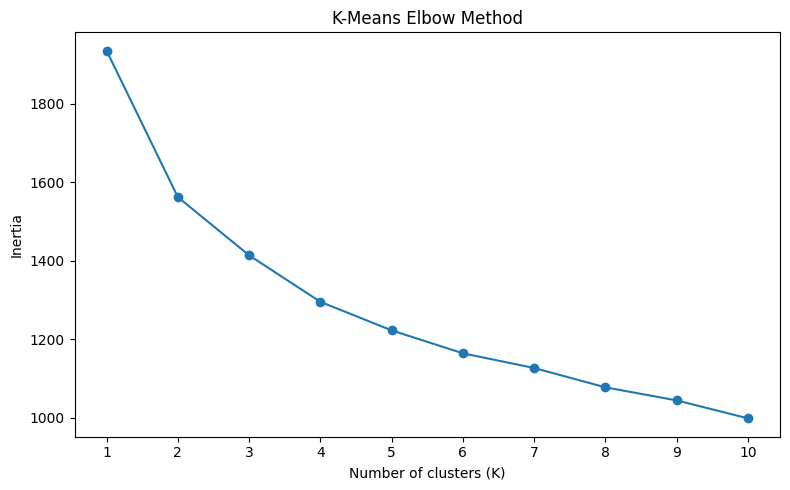

In [3]:
k_values = range(1, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_train)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig("../results/kmeans_elbow.png")
plt.show()

In [4]:
best_k = 4 

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_train)

print("Cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

Cluster sizes:
0    58
1    43
2    47
3    94
Name: count, dtype: int64


## Hierarchical Clustering

### Dendogram Analysis

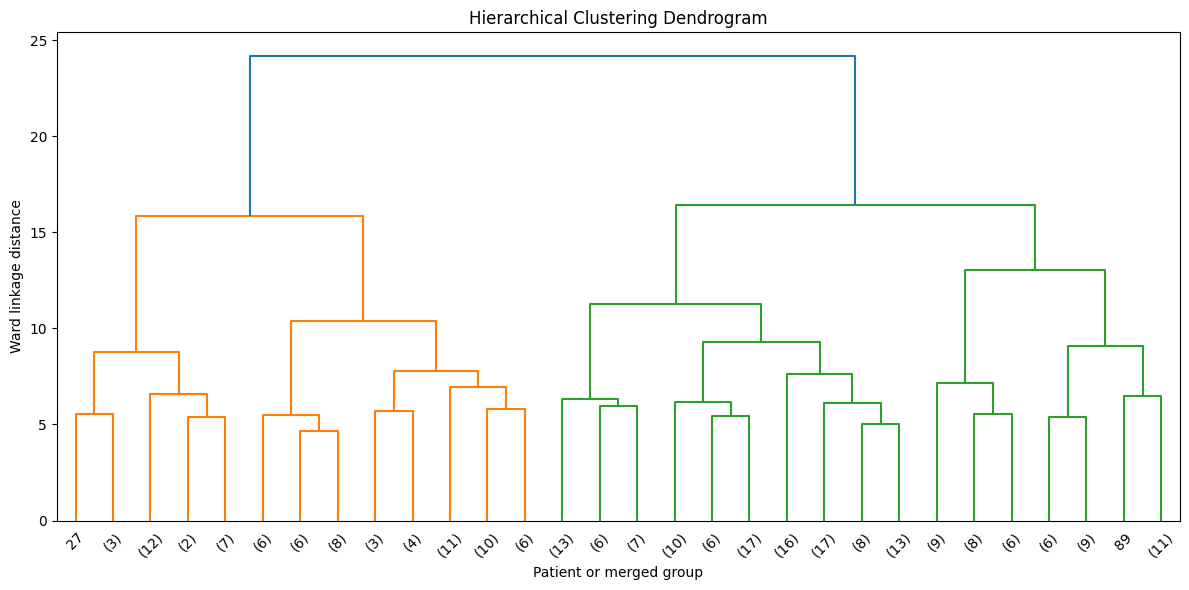

In [5]:
linkage_matrix = linkage(X_train, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(linkage_matrix,truncate_mode="lastp",p=30,show_leaf_counts=True)

plt.xlabel("Patient or merged group")
plt.ylabel("Ward linkage distance")
plt.title("Hierarchical Clustering Dendrogram")
plt.tight_layout()
plt.savefig("../results/hierarchical_dendrogram.png")
plt.show()

In [6]:
hierarchical_k = 2

hierarchical = AgglomerativeClustering(n_clusters=hierarchical_k,linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_train)

print("Cluster sizes:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Cluster sizes:
0    163
1     79
Name: count, dtype: int64


## Performance Comparison

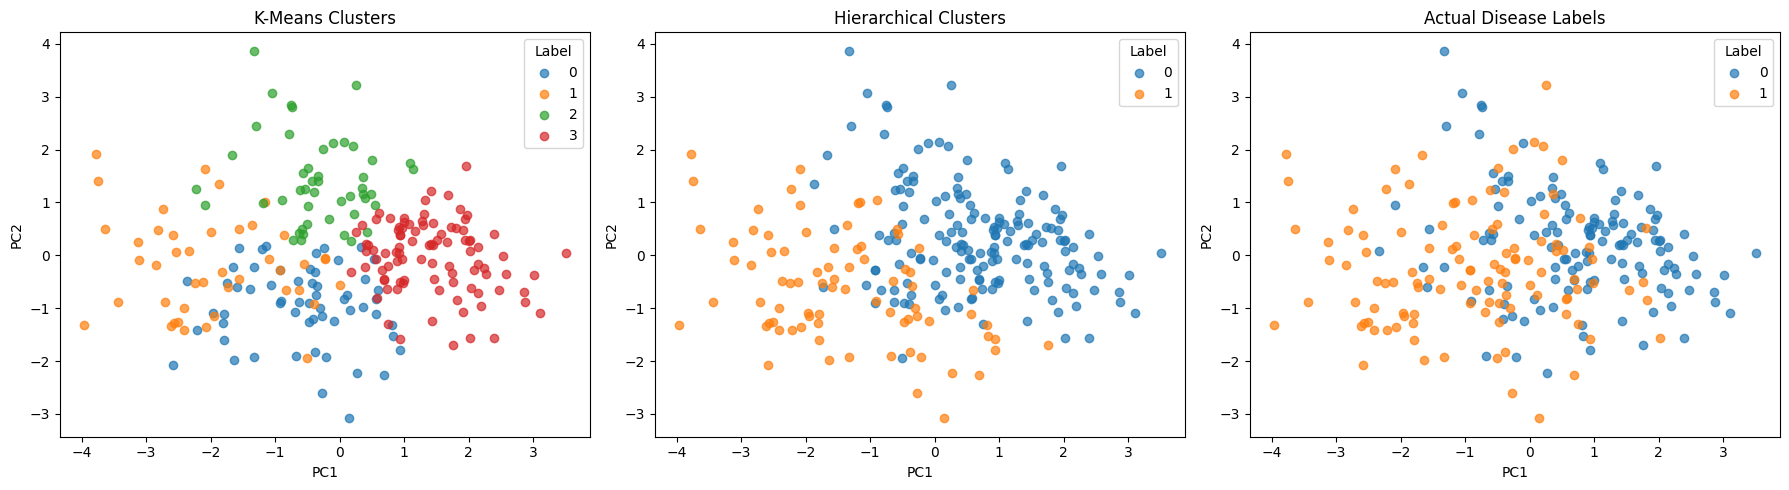

In [7]:
pca_visual = PCA(n_components=2)
plot_data = pca_visual.fit_transform(X_train)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plots = [
    (kmeans_labels, "K-Means Clusters"),
    (hierarchical_labels, "Hierarchical Clusters"),
    (y_train.to_numpy(), "Actual Disease Labels")
]

for ax, (labels, title) in zip(axes, plots):
    for label in sorted(set(labels)):
        mask = labels == label

        ax.scatter(plot_data[mask, 0],plot_data[mask, 1],label=str(label),alpha=0.7)

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(title="Label")

plt.tight_layout()
plt.savefig("../results/clustering_comparison.png")
plt.show()

In [8]:
kmeans_table = pd.crosstab(pd.Series(kmeans_labels, name="Cluster"),y_train.rename("Disease"))
hierarchical_table = pd.crosstab(pd.Series(hierarchical_labels, name="Cluster"),y_train.rename("Disease"))

print("K-Means vs disease labels:")
print(kmeans_table)

print("\nHierarchical clustering vs disease labels:")
print(hierarchical_table)

K-Means vs disease labels:
Disease   0   1
Cluster        
0        21  37
1         4  39
2        30  17
3        76  18

Hierarchical clustering vs disease labels:
Disease    0   1
Cluster         
0        112  51
1         19  60


In [9]:
clustering_metrics = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical"],
    "Clusters": [best_k, hierarchical_k],
    "Silhouette": [
        silhouette_score(X_train, kmeans_labels),
        silhouette_score(X_train, hierarchical_labels)
    ],
    "Adjusted_Rand_Index": [
        adjusted_rand_score(y_train, kmeans_labels),
        adjusted_rand_score(y_train, hierarchical_labels)
    ]
})

clustering_metrics

,Method,Clusters,Silhouette,Adjusted_Rand_Index
0,K-Means,4,0.145987,0.161958
1,Hierarchical,2,0.164934,0.173978


## Save Models and Results

In [10]:
joblib.dump(kmeans, "../models/kmeans.pkl")
joblib.dump(hierarchical, "../models/hierarchical.pkl")

cluster_assignments = pd.DataFrame({
    "Disease": y_train,
    "KMeans_cluster": kmeans_labels,
    "Hierarchical_cluster": hierarchical_labels
})

cluster_assignments.to_csv("../results/cluster_assignments.csv", index=False)
clustering_metrics.to_csv("../results/clustering_metrics.csv", index=False)

kmeans_table.to_csv("../results/kmeans_vs_disease.csv")
hierarchical_table.to_csv("../results/hierarchical_vs_disease.csv")

In [11]:
with open("../results/evaluation_metrics.txt", "a") as file:
    file.write("\n\nClustering Evaluation\n")
    file.write(clustering_metrics.round(4).to_string(index=False))
    file.write("\n")